In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 10 - Where does the public money go?
General-government expenditure by function (COFOG) and by economic nature, % of GDP. There is no official measure of 'bad spending': this notebook shows **composition** and where Italy departs from the other members. 2021-23 are distorted by one-off items (see the capital-transfer chart).

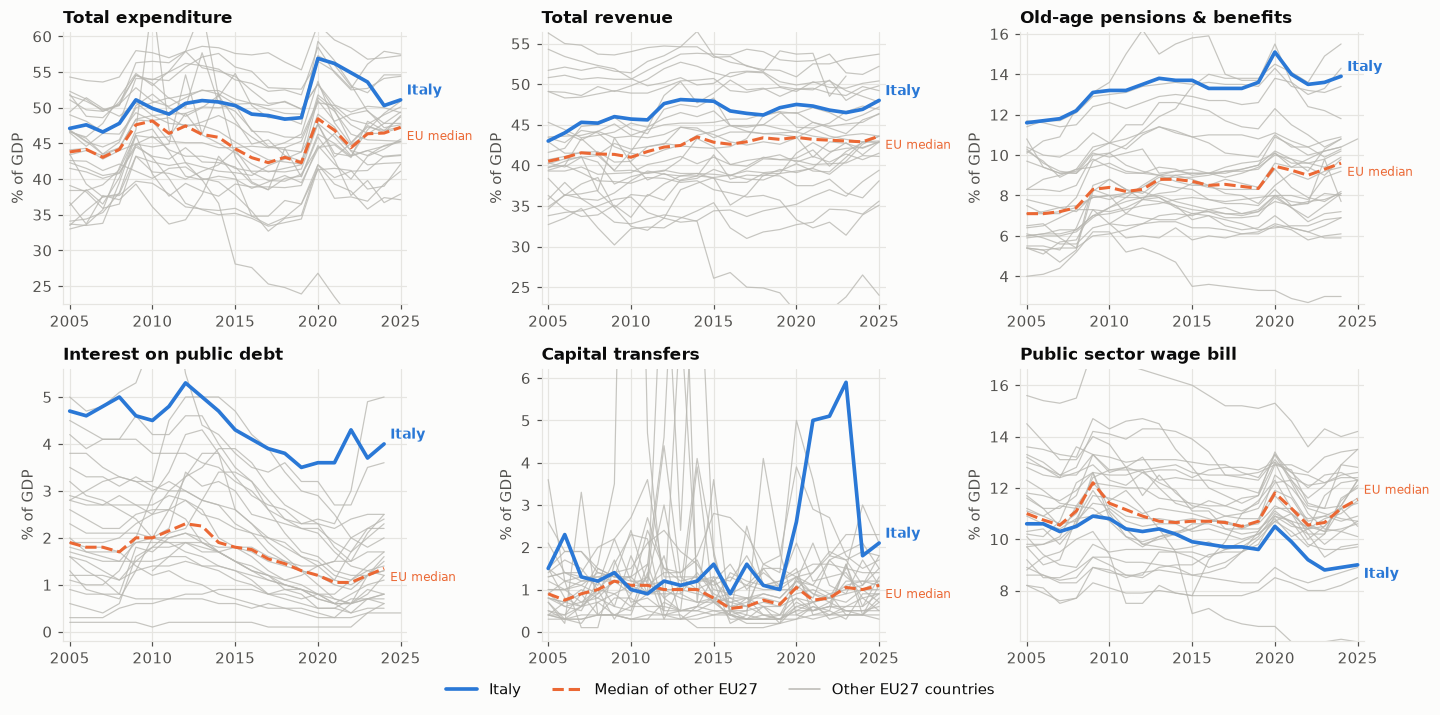

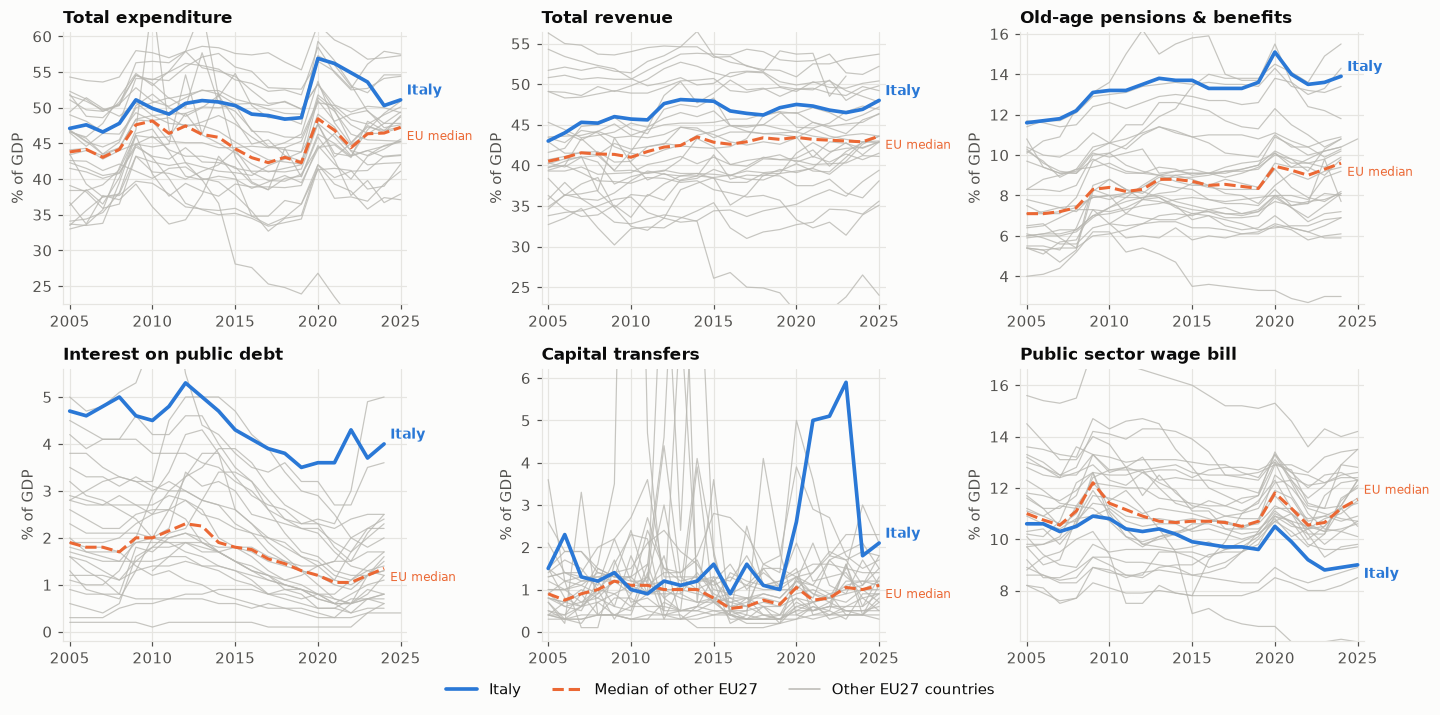

In [2]:
sp = load_spending()
items = [
    (spend_wide(sp, "TE", "nature"), "Total expenditure", "% of GDP"),
    (spend_wide(sp, "TR", "nature"), "Total revenue", "% of GDP"),
    (spend_wide(sp, "GF1002", "cofog"), "Old-age pensions & benefits", "% of GDP"),
    (spend_wide(sp, "GF0107", "cofog"), "Interest on public debt", "% of GDP"),
    (spend_wide(sp, "D9PAY", "nature"), "Capital transfers", "% of GDP"),
    (spend_wide(sp, "D1PAY", "nature"), "Public sector wage bill", "% of GDP"),
]
small_multiples_wide(items, ncols=3, name="10_spending_overview")

Total expenditure, Italy vs median of others (% GDP): {2005: (np.float64(47.1), np.float64(44.1)), 2019: (np.float64(48.4), np.float64(42.3)), 2024: (np.float64(50.4), np.float64(46.6))}


,2019,2024
Education,-0.8,-1.0
Other social protection,-0.7,-0.9
Economic affairs,-0.6,-0.5
Recreation & culture,-0.4,-0.4
Defence,0.2,-0.2
Health,0.8,-0.1
General services (excl. interest),0.1,-0.0
Public order & safety,0.1,0.1
Environment,0.2,0.2
Housing & community,-0.1,0.2


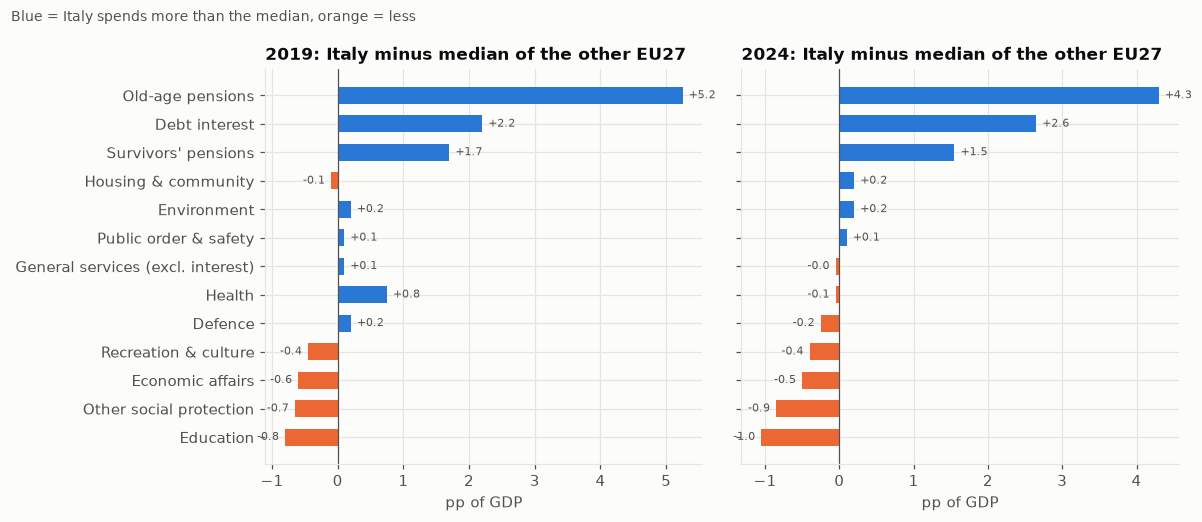

In [3]:
# Composition gap: Italy minus the median of the other members, by function, % of GDP
def gap(year):
    t = cofog_groups(sp, year); eu = [c for c in t.index if c in EU27_ISO3]
    return (t.loc[ITALY] - t.loc[[c for c in eu if c != ITALY]].median())
g19, g24 = gap(2019), gap(2024)
order = g24.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, g, yr in zip(axes, [g19, g24], [2019, 2024]):
    ax.barh(range(len(order)), g[order].values, color=[ITALY_C if v >= 0 else EU_C for v in g[order].values], height=0.6)
    ax.set_yticks(range(len(order)), order); ax.axvline(0, color=INK2, lw=0.8); ax.set_title(f"{yr}: Italy minus median of the other EU27"); ax.set_xlabel("pp of GDP")
    for i, v in enumerate(g[order].values): ax.annotate(f"{v:+.1f}", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points", ha="left" if v >= 0 else "right", va="center", fontsize=7, color=INK2)
fig.suptitle("Blue = Italy spends more than the median, orange = less", fontsize=9, color=INK2, x=0.01, ha="left"); fig.tight_layout(); save(fig, "10_cofog_gap")
tot = {y: spend_wide(sp, "TOTAL", "cofog").pipe(lambda w: (w.loc[y, ITALY], eu_median_ex_italy(w).loc[y])) for y in (2005, 2019, 2024)}
print("Total expenditure, Italy vs median of others (% GDP):", {y: (round(a, 1), round(b, 1)) for y, (a, b) in tot.items()})
display(pd.DataFrame({"2019": g19, "2024": g24}).loc[order].round(1))

Revenue 2019, Italy vs median (% GDP): direct taxes [np.float64(14.3), np.float64(9.4)] | social contributions [np.float64(13.4), np.float64(12.0)] | indirect taxes [np.float64(14.5), np.float64(14.1)] | total [np.float64(47.1), np.float64(43.2)]


,2019,2024
Public sector wages,-1.1,-2.3
Public investment (GFCF),-1.1,-0.6
Other current transfers,-0.3,-0.5
Intermediate consumption (goods & services),-0.1,-0.3
Subsidies,0.6,0.4
Capital transfers,0.4,0.8
Interest,2.0,2.6
Social benefits,5.7,5.1


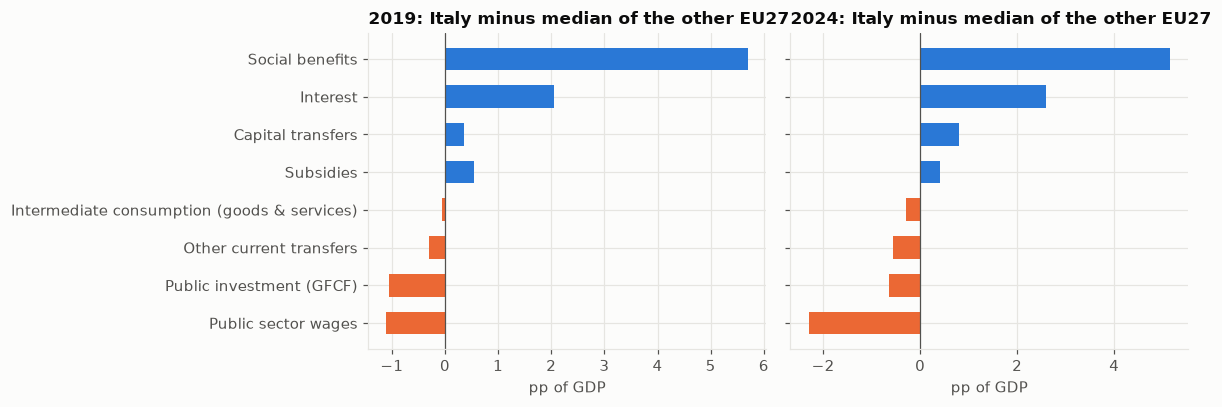

In [4]:
# The same gap by economic nature (not exhaustive: other items are omitted)
def ngap(year):
    rows = {}
    for it, lab in NATURE_LABELS.items():
        w = spend_wide(sp, it, "nature"); rows[lab] = w.loc[year, ITALY] - eu_median_ex_italy(w).loc[year]
    return pd.Series(rows)
n19, n24 = ngap(2019), ngap(2024)
order = n24.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, g, yr in zip(axes, [n19, n24], [2019, 2024]):
    ax.barh(range(len(order)), g[order].values, color=[ITALY_C if v >= 0 else EU_C for v in g[order].values], height=0.6)
    ax.set_yticks(range(len(order)), order); ax.axvline(0, color=INK2, lw=0.8); ax.set_title(f"{yr}: Italy minus median of the other EU27"); ax.set_xlabel("pp of GDP")
fig.tight_layout(); save(fig, "10_nature_gap")
rev = {k: (spend_wide(sp, k, "nature")[ITALY].loc[2019], eu_median_ex_italy(spend_wide(sp, k, "nature")).loc[2019]) for k in ["D5REC", "D61REC", "D2REC", "TR"]}
print("Revenue 2019, Italy vs median (% GDP): direct taxes", [round(x, 1) for x in rev["D5REC"]], "| social contributions", [round(x, 1) for x in rev["D61REC"]], "| indirect taxes", [round(x, 1) for x in rev["D2REC"]], "| total", [round(x, 1) for x in rev["TR"]])
display(pd.DataFrame({"2019": n19, "2024": n24}).loc[order].round(1))

Primary expenditure Italy vs median: {2005: (np.float64(42.6), np.float64(41.7)), 2010: (np.float64(45.6), np.float64(45.4)), 2015: (np.float64(46.2), np.float64(42.7)), 2019: (np.float64(45.3), np.float64(40.7)), 2023: (np.float64(50.0), np.float64(44.8)), 2024: (np.float64(46.4), np.float64(44.1))}


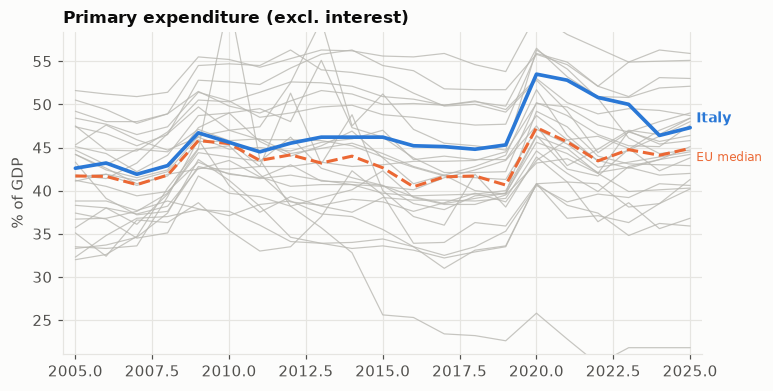

In [5]:
# Primary spending (total expenditure minus interest) vs the median, over time
te = spend_wide(sp, "TE", "nature"); it = spend_wide(sp, "D41PAY", "nature"); prim = te - it
fig, ax = plt.subplots(figsize=(7.5, 3.8)); line_wide(ax, prim, "Primary expenditure (excl. interest)", "% of GDP"); save(fig, "10_primary_spending")
print("Primary expenditure Italy vs median:", {y: (round(prim.loc[y, ITALY], 1), round(eu_median_ex_italy(prim).loc[y], 1)) for y in (2005, 2010, 2015, 2019, 2023, 2024)})

## Absolute amounts: Italy in million euro
Eurostat also publishes COFOG in million euro at current prices. Euro levels are shown for Italy only (they are not comparable across countries of different size); the cross-country comparison stays in % of GDP and % of total spending. Nominal growth includes inflation.

In [6]:
yrs = [2005, 2019, 2024]
eur = italy_cofog_euro(sp, yrs)
eur["nominal growth 2005-24, %"] = 100 * (eur["2024 MEUR"] / eur["2005 MEUR"] - 1)
display(eur.sort_values("2024 MEUR", ascending=False).round(1))
tot = eur[[f"{y} MEUR" for y in yrs]].sum(); print("Total (MEUR):", tot.round(0).to_dict(), "| nominal growth 2005-24: %.0f%%" % (100 * (tot["2024 MEUR"] / tot["2005 MEUR"] - 1)))

,2005 MEUR,2019 MEUR,2024 MEUR,2005 % of total,2019 % of total,2024 % of total,"nominal growth 2005-24, %"
Old-age pensions,174619.0,244532.0,306359.0,24.8,28.0,27.6,75.4
Health,101690.0,121075.0,146075.0,14.4,13.9,13.2,43.6
Economic affairs,59534.5,75918.8,112380.8,8.4,8.7,10.1,88.8
Other social protection,45465.0,89015.0,108563.0,6.4,10.2,9.8,138.8
Education,67153.6,71367.7,89179.9,9.5,8.2,8.0,32.8
Debt interest,70779.0,63712.0,87789.0,10.0,7.3,7.9,24.0
General services (excl. interest),70418.0,68466.0,82625.0,10.0,7.8,7.4,17.3
Survivors' pensions,36725.0,45367.0,53213.0,5.2,5.2,4.8,44.9
Public order & safety,28678.0,32921.0,39094.0,4.1,3.8,3.5,36.3
Defence,18913.0,23060.0,28301.0,2.7,2.6,2.6,49.6


Total (MEUR): {'2005 MEUR': 705365.0, '2019 MEUR': 873598.0, '2024 MEUR': 1109154.0} | nominal growth 2005-24: 57%


In [7]:
# Defence: where Italy ranks among the EU27 (descriptive placebo ranking over countries, no test), both units, 2024
for unit, lab in [("PC_GDP", "% of GDP"), ("PC_TOT", "% of total spending")]:
    w = spend_wide(sp, "GF02", unit=unit); r = w.loc[2024, [c for c in w.columns if c in EU27_ISO3]].dropna()
    print(f"Defence {lab}, 2024: Italy {r[ITALY]:.1f}, median of others {r.drop(ITALY).median():.1f}, rank {int(r.rank(ascending=False)[ITALY])}/{len(r)} (1 = highest)")
w = spend_wide(sp, "GF02", unit="MIO_EUR"); print("Italy defence, MEUR:", w[ITALY].dropna().loc[[2005, 2019, 2024]].round(0).to_dict(), "(COFOG covers the Defence function only: NATO-definition totals differ, not checked here)")

Defence % of GDP, 2024: Italy 1.3, median of others 1.6, rank 19/27 (1 = highest)
Defence % of total spending, 2024: Italy 2.6, median of others 3.2, rank 20/27 (1 = highest)
Italy defence, MEUR: {2005: 18913.0, 2019: 23060.0, 2024: 28301.0} (COFOG covers the Defence function only: NATO-definition totals differ, not checked here)


## Takeaways (Eurostat COFOG and national-accounts items; median = other EU27 members)
- **Italy spends more overall:** total expenditure was 47.1% of GDP in 2005, 48.4% in 2019 and 50.4% in 2024, against medians of 44.1%, 42.3% and 46.6%.
- **The excess is concentrated in three items.** In 2019 old-age pensions were +5.2 pp of GDP above the median, debt interest +2.2 and survivors' pensions +1.7 (2024: +4.3, +2.6, +1.5). Almost every other function is within about 1 pp of the median: education -0.8 (-1.0 in 2024), other social protection -0.7 (-0.9), economic affairs -0.6 (-0.5), health +0.8 (-0.1).
- **By economic nature (2024):** social benefits +5.1 pp, interest +2.6, capital transfers +0.8; the public-sector wage bill is 2.3 pp *below* the median (1.1 below in 2019), public investment 0.6 below (1.2 in 2019), purchases of goods and services 0.4 below. These aggregates show no sign of an oversized administration; they cannot show whether the money is spent well.
- **Primary spending** (excluding interest) was 45.3% of GDP in 2019 vs 40.7% median (+4.6 pp) and 46.4% vs 44.1% in 2024 (+2.3).
- **Revenue is also high** (2019: 47.1% of GDP vs 43.2%), mostly direct taxes (14.3% vs 9.4%) and social contributions (13.4% vs 12.0%); indirect taxes are at the median (14.5% vs 14.1%).
- **2021-23 are distorted.** Housing and community spending jumped from 0.4% of GDP (2019) to 2.4%, 3.3% and 4.4%, and capital transfers from 1.0% to 5.0%, 5.1% and 5.9%, before falling back in 2024 (0.8% and 1.7%). This is consistent with the building tax-credit schemes being recorded as spending, but the data do not name the scheme.
- **In euro (Italy only, current prices):** total general-government spending rose from EUR 705.4bn (2005) to 873.6bn (2019) and 1,109.2bn (2024), +57% nominal over 2005-24 (inflation included). Old-age pensions went from 174.6bn to 306.4bn (+75%; 27.6% of the 2024 total), health from 101.7bn to 146.1bn (+44%), debt interest from 70.8bn to 87.8bn (+24%). The 2024 euro figures reproduce the % of total spending in the table above.
- **Defence:** EUR 18.9bn (2005), 23.1bn (2019), 28.3bn (2024; +50%), 1.3% of GDP and 2.6% of total spending in 2024 against medians of 1.6% and 3.2% (19th of 27 and 20th of 27, 1 = highest; a descriptive ranking, no test). COFOG covers the Defence function only; NATO-definition totals differ and were not checked here. As elsewhere, descriptive, not causal.